#E23CSEU0868
# Lab-8
#B-29


In [1]:
!pip install pandas numpy nltk matplotlib seaborn wordcloud scikit-learn pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 70.4 MB/s eta 0:00:00


In [2]:
import os
import glob
import re
import string
import requests
import zipfile
import io
import json
import pandas as pd
import numpy as np
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries imported successfully.")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully.


In [3]:
from google.colab import drive

repo_url = (
    "https://github.com/WuraolaOyewusi/"
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing"
)

zip_url = repo_url + "/archive/refs/heads/main.zip"
response = requests.get(zip_url, timeout=60)

if response.status_code != 200:
    zip_url = repo_url + "/archive/refs/heads/master.zip"
    response = requests.get(zip_url, timeout=60)

response.raise_for_status()

extract_dir = "/content/health_headlines"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(extract_dir)

print("Dataset repository downloaded successfully.")

Dataset repository downloaded successfully.


In [4]:
csv_files = glob.glob(
    os.path.join(extract_dir, "**", "*.csv"),
    recursive=True
)

json_files = glob.glob(
    os.path.join(extract_dir, "**", "*.json"),
    recursive=True
)

data_files = csv_files + json_files

print("Available data files:")
for file in data_files:
    print(file)

if not data_files:
    raise FileNotFoundError(
        "No CSV or JSON files found. Check the repository's file structure."
    )

Available data files:
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Substance_Abuse_and_Addiction_Journals_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Adult_Immunization_Features_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Adverse_Drug_Reaction_Perspective_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Patient_Safety_Related_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Substance_Abuse_and_Addiction_News_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Adverse_Drug_Reaction_News_Headlines.csv
/content/health_headlines/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Adverse_Drug_Re

In [5]:
dataframes = []

for file in data_files:
    try:
        if file.endswith(".csv"):
            temp_df = pd.read_csv(file)
        else:
            try:
                temp_df = pd.read_json(file)
            except ValueError:
                temp_df = pd.read_json(file, lines=True)

        if not temp_df.empty:
            temp_df["source_file"] = os.path.basename(file)
            dataframes.append(temp_df)

    except Exception as e:
        print(f"Could not read {file}: {e}")

if not dataframes:
    raise ValueError("No dataset could be loaded successfully.")

df = pd.concat(dataframes, ignore_index=True, sort=False)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (118215, 6)

Column names:
['Date', 'Source', 'Headlines', 'Teaser', 'source_file', 'Category']


,Date,Source,Headlines,Teaser,source_file,Category
0,January 2003,Health Affairs,Private Health Insurance for Mental Health and...,The decline in spending between in the 1990s i...,Substance_Abuse_and_Addiction_Journals_Headlin...,NaN
1,September 2002,CHEST,Passive Smoking Exposure: Chronic Bronchitis a...,The prevalence of passive smoke exposure at ho...,Substance_Abuse_and_Addiction_Journals_Headlin...,NaN
2,October 2002,Morbidity & Mortality Weekly Report,Usual Sources of Cigarettes for Middle and Hig...,The percentages of students who reported steal...,Substance_Abuse_and_Addiction_Journals_Headlin...,NaN
3,September 2002,CHEST,Involuntary Smoking and Asthma Severity in Chi...,Involuntary smoking by children has been linke...,Substance_Abuse_and_Addiction_Journals_Headlin...,NaN
4,August 2002,CHEST,Hospital Initiatives in Promoting Smoking Cess...,Of the 50 million smokers in the United States...,Substance_Abuse_and_Addiction_Journals_Headlin...,NaN


In [6]:
text_keywords = [
    "headline", "title", "teaser", "description",
    "summary", "abstract", "article", "text", "content"
]

text_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in text_keywords)
    and col.lower() != "source_file"
]

print("Detected text columns:", text_columns)

if not text_columns:

    text_columns = [
        col for col in df.columns
        if df[col].dtype == "object"
        and col.lower() != "source_file"
    ]

if not text_columns:
    raise ValueError("No suitable text columns were found.")

df["text"] = (
    df[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

df = df[df["text"] != ""].drop_duplicates(subset=["text"])
df = df.reset_index(drop=True)

print("Selected columns:", text_columns)
print("Usable text records:", len(df))
display(df[["text"]].head())

Detected text columns: ['Headlines', 'Teaser']
Selected columns: ['Headlines', 'Teaser']
Usable text records: 31720


,text
0,Private Health Insurance for Mental Health and...
1,Passive Smoking Exposure: Chronic Bronchitis a...
2,Usual Sources of Cigarettes for Middle and Hig...
3,Involuntary Smoking and Asthma Severity in Chi...
4,Hospital Initiatives in Promoting Smoking Cess...


In [7]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

custom_stopwords = {
    "said", "says", "new", "one", "two", "year", "years",
    "may", "also", "could", "would", "use", "used"
}

stop_words.update(custom_stopwords)

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = word_tokenize(text)

    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]

    return cleaned_tokens

df["tokens"] = df["text"].apply(clean_text)

df["cleaned_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))

df = df[df["cleaned_text"].str.strip() != ""].reset_index(drop=True)

print("Original and cleaned text samples:\n")

for i, row in df[["text", "cleaned_text"]].head(5).iterrows():
    print(f"Sample {i + 1}")
    print("Original:", row["text"])
    print("Cleaned :", row["cleaned_text"])

Original and cleaned text samples:

Sample 1
Original: Private Health Insurance for Mental Health and Substance Abuse The decline in spending between in the 1990s is a change from trends in the 1980s, when rising costs alarmed policymakers and employers.
Cleaned : private health insurance mental health substance abuse decline spending change trend rising cost alarmed policymakers employer
Sample 2
Original: Passive Smoking Exposure: Chronic Bronchitis and Asthma Risks The prevalence of passive smoke exposure at home and at the workplace is still high throughout Europe.
Cleaned : passive smoking exposure chronic bronchitis asthma risk prevalence passive smoke exposure home workplace still high throughout europe
Sample 3
Original: Usual Sources of Cigarettes for Middle and High School Students The percentages of students who reported stealing cigarettes or
Cleaned : usual source cigarette middle high school student percentage student reported stealing cigarette
Sample 4
Original: Involun

In [8]:
from collections import Counter

all_words = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

word_freq = Counter(all_words)

top_20_words = word_freq.most_common(20)

frequency_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

print("Top 20 most frequent words:")
display(frequency_df)

print("Total cleaned words:", len(all_words))
print("Unique words:", len(word_freq))

Top 20 most frequent words:


,Word,Frequency
0,patient,10384
1,risk,6260
2,study,5671
3,drug,4994
4,cancer,4720
5,pain,4603
6,treatment,4526
7,disease,3353
8,therapy,2771
9,trial,2530


Total cleaned words: 618838
Unique words: 24801


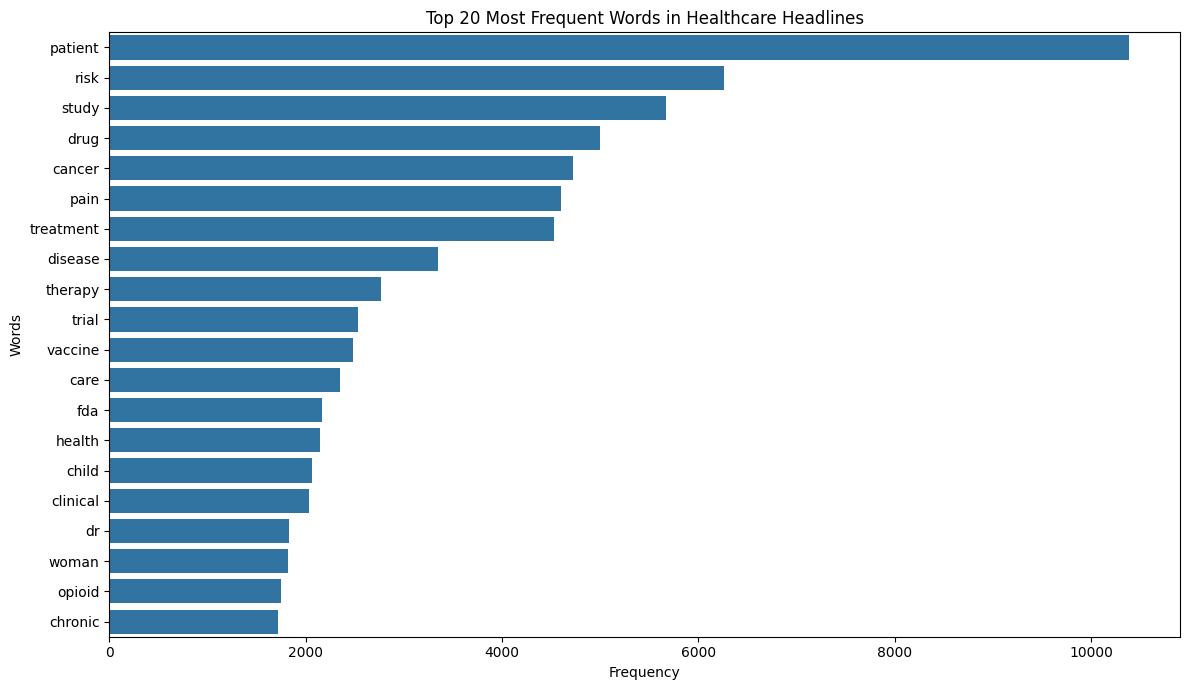

In [9]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=frequency_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words in Healthcare Headlines")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

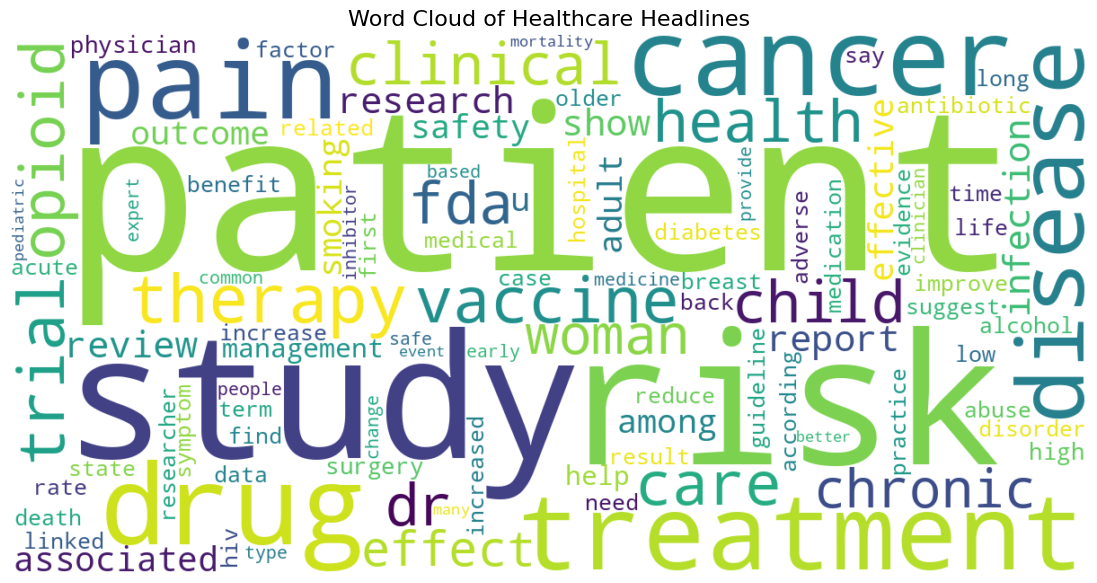

In [10]:
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    max_words=100,
    collocations=False
).generate(" ".join(all_words))

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Healthcare Headlines", fontsize=16)
plt.show()

In [11]:
vectorizer = CountVectorizer(
    max_features=5000,
    min_df=1,
    max_df=0.95
)

dtm = vectorizer.fit_transform(df["cleaned_text"])

print("Document-term matrix shape:", dtm.shape)
print("Number of documents:", dtm.shape[0])
print("Number of unique vocabulary terms:", dtm.shape[1])

Document-term matrix shape: (31720, 5000)
Number of documents: 31720
Number of unique vocabulary terms: 5000


In [12]:
n_topics = 5

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=20
)

lda_model.fit(dtm)

print("LDA model trained successfully.")

LDA model trained successfully.


In [13]:
feature_names = vectorizer.get_feature_names_out()

n_top_words = 5

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-n_top_words:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

Topic 1: vaccine, patient, health, physician, care
Topic 2: risk, study, woman, patient, diabetes
Topic 3: pain, treatment, patient, drug, therapy
Topic 4: cancer, dr, drug, trial, antibiotic
Topic 5: patient, surgery, hiv, study, outcome


In [15]:
!pip install --upgrade pyLDAvis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa"
)

pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
import pyLDAvis

# Save the visualization
output_path = "/content/healthcare_lda_visualization.html"
pyLDAvis.save_html(vis, output_path)

print("Visualization saved successfully!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Visualization saved successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [22]:
from IPython.display import display, HTML

with open("/content/healthcare_lda_visualization.html", "r", encoding="utf-8") as f:
    html_content = f.read()

display(HTML(html_content))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [23]:
topic_probabilities = lda_model.transform(dtm)

df["dominant_topic"] = (
    topic_probabilities.argmax(axis=1) + 1
)

df["topic_probability"] = (
    topic_probabilities.max(axis=1)
)

print("Headlines with their dominant topics:")
display(
    df[["text", "dominant_topic", "topic_probability"]].head(10)
)

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Headlines with their dominant topics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text,dominant_topic,topic_probability
0,Private Health Insurance for Mental Health and...,1,0.706731
1,Passive Smoking Exposure: Chronic Bronchitis a...,2,0.735331
2,Usual Sources of Cigarettes for Middle and Hig...,1,0.932446
3,Involuntary Smoking and Asthma Severity in Chi...,2,0.627618
4,Hospital Initiatives in Promoting Smoking Cess...,1,0.670916
5,Environmental Tobacco Smoke Exposure During Tr...,2,0.663065
6,Treatment of a Young Adult Taking Gamma Butyro...,2,0.439335
7,Treating Tobacco Use and Dependence Read about...,5,0.689755
8,Alcohol Use Among US Women of Childbearing Age...,2,0.937983
9,Link Between Parental Alcoholism and Childhood...,2,0.848997


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

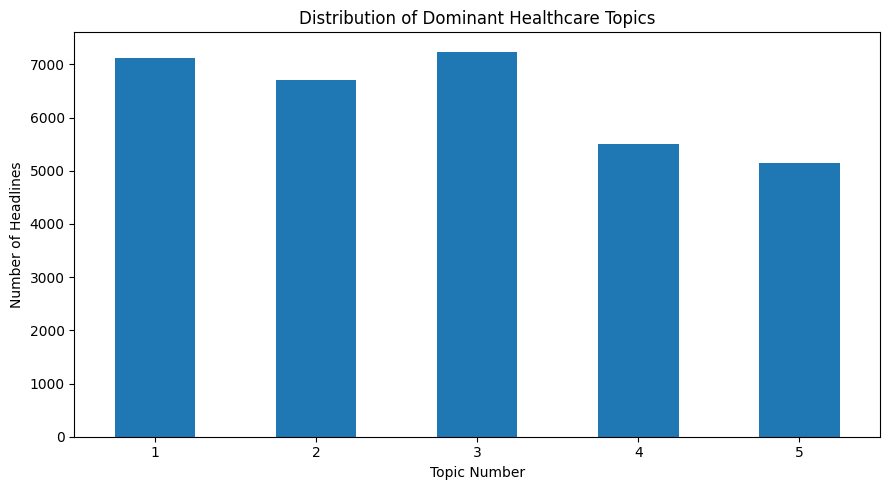

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
topic_counts = (
    df["dominant_topic"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))
topic_counts.plot(kind="bar")

plt.title("Distribution of Dominant Healthcare Topics")
plt.xlabel("Topic Number")
plt.ylabel("Number of Headlines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()